# Neural Networks: NumPy to TensorFlow

This notebook starts with tiny neural networks, then uses real image datasets. Run the cells from top to bottom.

The image sections need TensorFlow and an internet connection the first time they download their data.

We load the tools used in the notebook and set a seed so small examples are repeatable.

In [1]:
import os
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

np.random.seed(42)

try:
    import tensorflow as tf
    tf.keras.utils.set_random_seed(42)
    print(f"TensorFlow {tf.__version__} is ready.")
except ImportError:
    tf = None
    print("TensorFlow is not installed. Install it with: pip install tensorflow")

TensorFlow 2.22.0-rc0 is ready.


## 1. A Small Feedforward Network

A feedforward network sends numbers through layers. This tiny example has one hidden layer and one output.

In [2]:
features = np.array([[0.2, 0.7, 0.1], [0.9, 0.1, 0.4], [0.3, 0.5, 0.8]])
hidden_weights = np.random.randn(3, 4) * 0.5
hidden_bias = np.zeros((1, 4))
output_weights = np.random.randn(4, 1) * 0.5
output_bias = np.zeros((1, 1))

hidden_values = 1 / (1 + np.exp(-(features @ hidden_weights + hidden_bias)))
predictions = 1 / (1 + np.exp(-(hidden_values @ output_weights + output_bias)))

print("Input shape:", features.shape)
print("Hidden layer shape:", hidden_values.shape)
print("Output probabilities:\n", predictions.round(3))

Input shape: (3, 3)
Hidden layer shape: (3, 4)
Output probabilities:
 [[0.245]
 [0.25 ]
 [0.248]]


## 2. A Custom Activation

An activation adds a useful bend to a layer's output. Here we write tanh ourselves and use it in the hidden layer.

In [3]:
def custom_tanh(values):
    positive = np.exp(values)
    negative = np.exp(-values)
    return (positive - negative) / (positive + negative)

custom_hidden = custom_tanh(features @ hidden_weights + hidden_bias)
custom_output = 1 / (1 + np.exp(-(custom_hidden @ output_weights + output_bias)))

print("Custom tanh hidden values:\n", custom_hidden.round(3))
print("Network output probabilities:\n", custom_output.round(3))

Custom tanh hidden values:
 [[-0.056 -0.069  0.533  0.378]
 [ 0.117  0.035  0.271  0.558]
 [-0.17   0.137  0.297  0.23 ]]
Network output probabilities:
 [[0.376]
 [0.399]
 [0.384]]


## 3. Manual Forward Propagation

Forward propagation calculates each layer in order. This function uses weights and biases supplied by us.

In [4]:
def manual_forward(inputs, weights_1, bias_1, weights_2, bias_2):
    hidden = np.maximum(0, inputs @ weights_1 + bias_1)
    scores = hidden @ weights_2 + bias_2
    shifted_scores = scores - np.max(scores, axis=1, keepdims=True)
    probabilities = np.exp(shifted_scores)
    return probabilities / np.sum(probabilities, axis=1, keepdims=True)

sample_inputs = np.array([[1.0, 0.5, -0.2], [0.1, 0.8, 0.3]])
weights_1 = np.array([[0.2, -0.1, 0.4, 0.3], [0.5, 0.2, -0.3, 0.1], [-0.4, 0.6, 0.2, -0.2]])
bias_1 = np.array([[0.1, 0.0, 0.1, -0.1]])
weights_2 = np.array([[0.3, -0.2], [-0.1, 0.4], [0.5, 0.2], [-0.3, 0.1]])
bias_2 = np.array([[0.0, 0.1]])

class_probabilities = manual_forward(sample_inputs, weights_1, bias_1, weights_2, bias_2)
print("Class probabilities:\n", class_probabilities.round(3))
print("Predicted classes:", np.argmax(class_probabilities, axis=1))

Class probabilities:
 [[0.548 0.452]
 [0.484 0.516]]
Predicted classes: [0 1]


## 4. Dataset Loss and Learning

Loss measures how wrong predictions are. We calculate binary cross-entropy, then adjust weights with gradient descent.

In [5]:
def sigmoid(values):
    return 1 / (1 + np.exp(-np.clip(values, -30, 30)))

def dataset_loss(inputs, labels, weights, bias):
    probabilities = sigmoid(inputs @ weights + bias)
    clipped = np.clip(probabilities, 1e-7, 1 - 1e-7)
    return -np.mean(labels * np.log(clipped) + (1 - labels) * np.log(1 - clipped))

training_inputs = np.array([[0.0, 0.0], [0.0, 1.0], [1.0, 0.0], [1.0, 1.0], [0.2, 0.1], [0.1, 0.9], [0.9, 0.2], [0.8, 0.9]])
training_labels = np.array([[0], [0], [0], [1], [0], [0], [0], [1]])
binary_weights = np.zeros((2, 1))
binary_bias = np.zeros((1, 1))
print("Starting loss:", round(dataset_loss(training_inputs, training_labels, binary_weights, binary_bias), 4))

learning_rate = 0.8
for epoch in range(2000):
    probabilities = sigmoid(training_inputs @ binary_weights + binary_bias)
    weight_gradient = training_inputs.T @ (probabilities - training_labels) / len(training_inputs)
    bias_gradient = np.mean(probabilities - training_labels, axis=0, keepdims=True)
    binary_weights -= learning_rate * weight_gradient
    binary_bias -= learning_rate * bias_gradient

final_loss = dataset_loss(training_inputs, training_labels, binary_weights, binary_bias)
final_predictions = (sigmoid(training_inputs @ binary_weights + binary_bias) >= 0.5).astype(int)
print("Final loss:", round(final_loss, 4))
print("Training accuracy:", f"{np.mean(final_predictions == training_labels):.1%}")

Starting loss: 0.6931
Final loss: 0.0205
Training accuracy: 100.0%


## 5. MNIST with TensorFlow

MNIST contains handwritten digits. This model learns to choose one of ten digit labels.

In [6]:
if tf is None:
    raise ImportError("Install TensorFlow with `pip install tensorflow`, then restart the kernel.")

(mnist_x_train, mnist_y_train), (mnist_x_test, mnist_y_test) = tf.keras.datasets.mnist.load_data()
mnist_x_train = mnist_x_train.astype("float32") / 255.0
mnist_x_test = mnist_x_test.astype("float32") / 255.0

mnist_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(10, activation="softmax")
])
mnist_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
mnist_history = mnist_model.fit(mnist_x_train, mnist_y_train, epochs=5, batch_size=128, validation_split=0.1, verbose=2)
mnist_loss, mnist_accuracy = mnist_model.evaluate(mnist_x_test, mnist_y_test, verbose=0)
print(f"MNIST test accuracy: {mnist_accuracy:.2%}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Epoch 1/5
422/422 - 2s - 6ms/step - accuracy: 0.8800 - loss: 0.4233 - val_accuracy: 0.9547 - val_loss: 0.1729
Epoch 2/5
422/422 - 1s - 3ms/step - accuracy: 0.9404 - loss: 0.2080 - val_accuracy: 0.9668 - val_loss: 0.1217
Epoch 3/5
422/422 - 1s - 3ms/step - accuracy: 0.9546 - loss: 0.1551 - val_accuracy: 0.9723 - val_loss: 0.0981
Epoch 4/5
422/422 - 1s - 3ms/step - accuracy: 0.9616 - loss: 0.1292 - val_accuracy: 0.9743 - val_loss: 0.0874
Epoch 5/5
422/422 - 1s - 3ms/step - accuracy: 0.9679 - loss: 0.1076 - val_accuracy: 0.9770 - val_loss: 0.0805
MNIST test accuracy: 97.25%


## 6. Fashion-MNIST with Keras

Fashion-MNIST has pictures of clothing. We train the same kind of model and check its test accuracy.

In [7]:
fashion_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
(fashion_x_train, fashion_y_train), (fashion_x_test, fashion_y_test) = tf.keras.datasets.fashion_mnist.load_data()
fashion_x_train = fashion_x_train.astype("float32") / 255.0
fashion_x_test = fashion_x_test.astype("float32") / 255.0

fashion_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(10, activation="softmax")
])
fashion_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
fashion_history = fashion_model.fit(fashion_x_train, fashion_y_train, epochs=6, batch_size=128, validation_split=0.1, verbose=2)
fashion_loss, fashion_accuracy = fashion_model.evaluate(fashion_x_test, fashion_y_test, verbose=0)
print(f"Fashion-MNIST test accuracy: {fashion_accuracy:.2%}")

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/6
422/422 - 2s - 5ms/step - accuracy: 0.7904 - loss: 0.6089 - val_accuracy: 0.8437 - val_loss: 0.4357
Epoch 2/6
422/422 - 1s - 3ms/step - accuracy: 0.8481 - loss: 0.4294 - val_accuracy: 0.8602 - val_loss: 0.3849
Epoch 3/6
422/422 - 1s - 3ms/step - accuracy: 0.8629 - loss: 0.3874 - val_accuracy: 0.8640 - val_loss: 0.3705
Epoch 4/6
422/422 - 1s - 3ms/step - accuracy: 0.8704 - loss: 0.3630 - val_accuracy: 0.8705 - val_loss: 0.3521
Epoch 5/6
422/422 - 1s - 3ms/step - accuracy: 0.8761 - loss: 0.3456 - val_accuracy: 0.8733 - val_loss: 0.3468
Epoch 6/6
422/422 - 1s - 3ms/step - accuracy: 0.8793 - loss: 0.3304 - val_accuracy: 0.8762 - val_loss: 0.3370
Fashion-MNIST test accuracy: 87.32%


## 7. Cats Versus Dogs CNN

A CNN looks for image patterns. We use a tiny public sample of 50 images so it downloads quickly, then inspect its wrong guesses. More images would give a stronger accuracy estimate.

In [4]:
if tf is None:
    raise ImportError("Install TensorFlow with `pip install tensorflow`, then restart the kernel.")

import pyarrow.parquet as parquet

parquet_url = "https://huggingface.co/datasets/hf-internal-testing/cats_vs_dogs_sample/resolve/refs%2Fconvert%2Fparquet/default/train/0000.parquet"
parquet_path = tf.keras.utils.get_file("cats_vs_dogs_sample.parquet", origin=parquet_url, cache_subdir="datasets")
examples = parquet.read_table(parquet_path).to_pylist()
image_size = (64, 64)
images = []
labels = []
for example in examples:
    image = tf.io.decode_image(example["image"]["bytes"], channels=3, expand_animations=False)
    image = tf.image.resize(image, image_size).numpy() / 255.0
    images.append(image)
    labels.append(example["labels"])
images = np.asarray(images, dtype=np.float32)
labels = np.asarray(labels, dtype=np.int32)
class_names = {0: "cat", 1: "dog"}

train_indices = []
validation_indices = []
for class_index in (0, 1):
    class_indices = np.flatnonzero(labels == class_index)
    np.random.shuffle(class_indices)
    split_point = int(len(class_indices) * 0.8)
    train_indices.extend(class_indices[:split_point])
    validation_indices.extend(class_indices[split_point:])
train_indices = np.asarray(train_indices)
validation_indices = np.asarray(validation_indices)
train_images = images[train_indices]
train_labels = labels[train_indices]
validation_images = images[validation_indices]
validation_labels = labels[validation_indices]
print(f"Training images: {len(train_images)} | Validation images: {len(validation_images)}")
print("Training class counts:", {class_names[index]: int(np.sum(train_labels == index)) for index in (0, 1)})
print("Validation class counts:", {class_names[index]: int(np.sum(validation_labels == index)) for index in (0, 1)})

cats_dogs_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(image_size[0], image_size[1], 3)),
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.Conv2D(16, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation="sigmoid")
])
cats_dogs_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
early_stopping = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
cats_dogs_model.fit(
    train_images, train_labels, epochs=40, batch_size=8,
    validation_data=(validation_images, validation_labels), callbacks=[early_stopping], verbose=2
)
dogs_loss, dogs_accuracy = cats_dogs_model.evaluate(validation_images, validation_labels, verbose=0)
print(f"Cats-versus-dogs validation accuracy: {dogs_accuracy:.2%}")

Training images: 40 | Validation images: 10
Training class counts: {'cat': 20, 'dog': 20}
Validation class counts: {'cat': 5, 'dog': 5}
Epoch 1/40
5/5 - 2s - 318ms/step - accuracy: 0.4750 - loss: 0.6941 - val_accuracy: 0.6000 - val_loss: 0.6931
Epoch 2/40
5/5 - 0s - 27ms/step - accuracy: 0.4250 - loss: 0.6956 - val_accuracy: 0.5000 - val_loss: 0.6926
Epoch 3/40
5/5 - 0s - 25ms/step - accuracy: 0.6000 - loss: 0.6912 - val_accuracy: 0.7000 - val_loss: 0.6929
Epoch 4/40
5/5 - 0s - 24ms/step - accuracy: 0.5250 - loss: 0.6924 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 5/40
5/5 - 0s - 26ms/step - accuracy: 0.5000 - loss: 0.6950 - val_accuracy: 0.4000 - val_loss: 0.6939
Epoch 6/40
5/5 - 0s - 25ms/step - accuracy: 0.5250 - loss: 0.6966 - val_accuracy: 0.5000 - val_loss: 0.6950
Epoch 7/40
5/5 - 0s - 27ms/step - accuracy: 0.5000 - loss: 0.6924 - val_accuracy: 0.5000 - val_loss: 0.6965
Epoch 8/40
5/5 - 0s - 24ms/step - accuracy: 0.5500 - loss: 0.6924 - val_accuracy: 0.5000 - val_loss: 0.6975

The validation images show how the model performs on pictures it did not train on. Here we display up to nine wrong guesses.

Misclassified validation images: 5 of 10


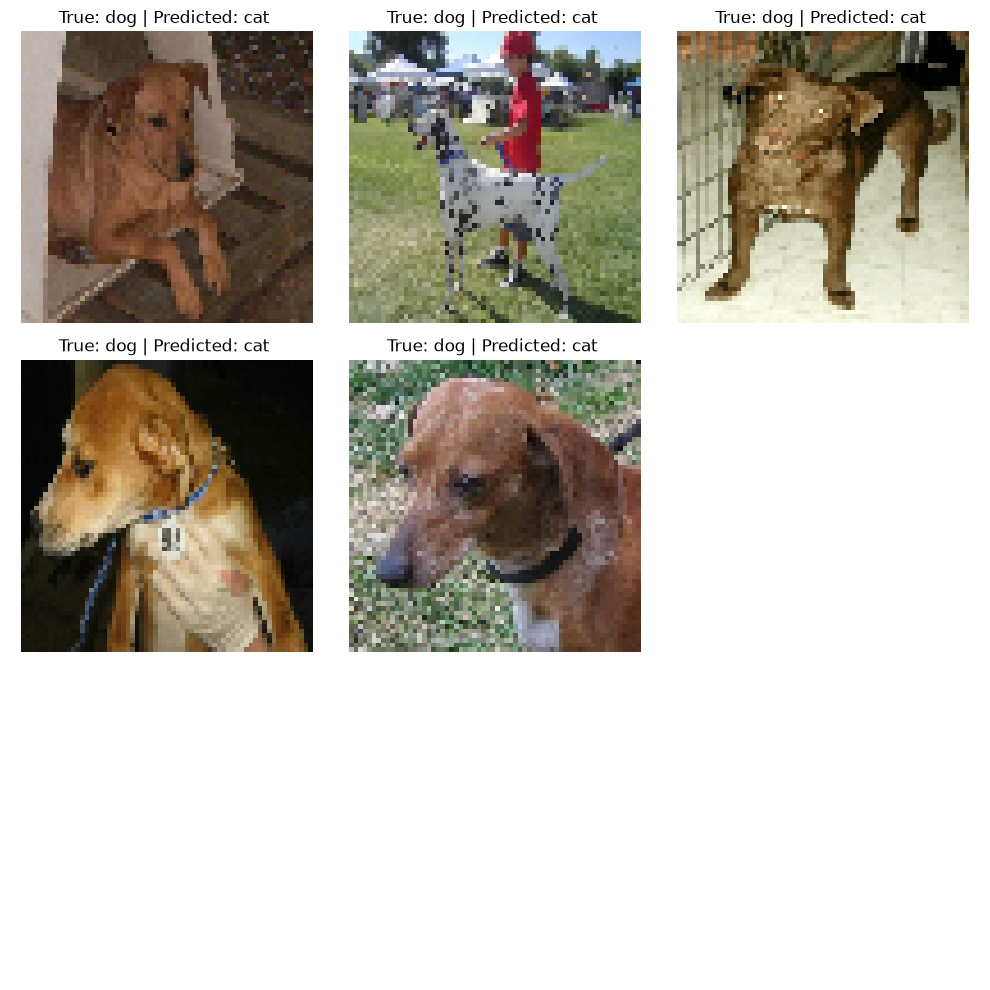

In [5]:
dog_probabilities = cats_dogs_model.predict(validation_images, verbose=0).ravel()
predicted_labels = (dog_probabilities >= 0.5).astype(int)
wrong_indices = np.flatnonzero(predicted_labels != validation_labels)
print(f"Misclassified validation images: {len(wrong_indices)} of {len(validation_labels)}")

if len(wrong_indices) == 0:
    print("No mistakes were found in this validation set.")
else:
    shown_indices = wrong_indices[:9]
    figure, axes = plt.subplots(3, 3, figsize=(10, 10))
    for axis, image_index in zip(axes.flat, shown_indices):
        axis.imshow(validation_images[image_index])
        axis.set_title(f"True: {class_names[int(validation_labels[image_index])]} | Predicted: {class_names[int(predicted_labels[image_index])]} ")
        axis.axis("off")
    for axis in axes.flat[len(shown_indices):]:
        axis.axis("off")
    plt.tight_layout()
    plt.show()

## What We Built

We built a small network from NumPy, wrote an activation and loss, and trained image classifiers with Keras. The final plot helps us see what the CNN still confuses.